In [1]:
# Time Series Aalysis for 'Flights ' dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.tsaplots import plot_acf,plot_pacf
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
import math

In [2]:
df = sns.load_dataset('flights')
df.head()

,year,month,passengers
0,1949,Jan,112
1,1949,Feb,118
2,1949,Mar,132
3,1949,Apr,129
4,1949,May,121


In [3]:
df['yearMonth'] = pd.to_datetime('01-'+df['month'].astype(str)+'-'+df['year'].astype(str))
df.set_index('yearMonth',inplace=True)
df.head()

,year,month,passengers
yearMonth,,,
1949-01-01,1949,Jan,112
1949-02-01,1949,Feb,118
1949-03-01,1949,Mar,132
1949-04-01,1949,Apr,129
1949-05-01,1949,May,121


In [4]:
airP = df[['passengers']].copy(deep=True)
airP.head()

,passengers
yearMonth,
1949-01-01,112
1949-02-01,118
1949-03-01,132
1949-04-01,129
1949-05-01,121


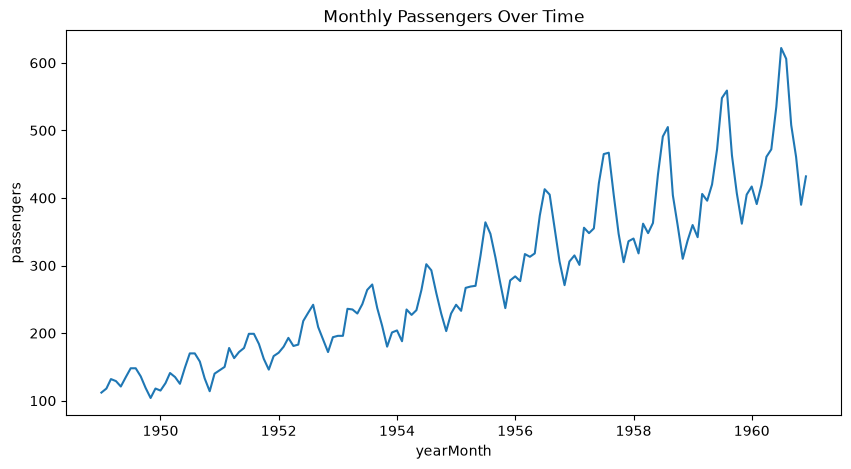

In [5]:
# Visualize initial data
plt.figure(figsize=(10,5))
sns.lineplot(x=airP.index , y=airP['passengers'])
plt.title('Monthly Passengers Over Time')
plt.show()

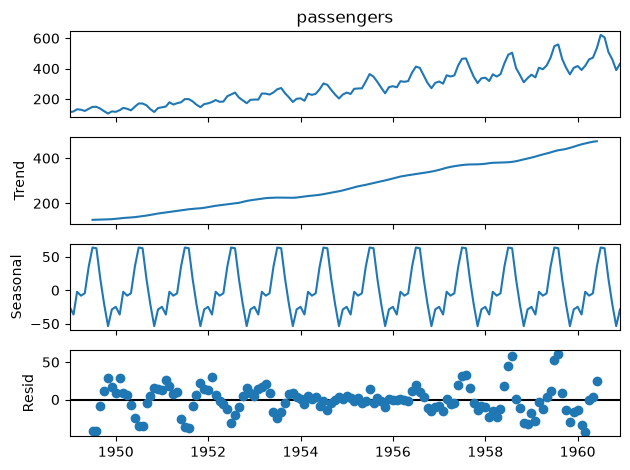

In [6]:
# Decompose to check trend and seasonality
decomposition = seasonal_decompose(airP.passengers, period=12)
decomposition.plot()
plt.show()

In [7]:
# Stationary check
def test_stationarity(dataFrame, var, window=12):
    dataFrame['rollMean'] = dataFrame[var].rolling(window=window).mean()
    dataFrame['rollStd'] = dataFrame[var].rolling(window=window).std()
    adf_result = adfuller(dataFrame[var])
    p_value = adf_result[1]
    print(f'ADF p-value : {p_value:.4f}')
    if p_value < 0.05:
        print('The Time Series is Stationary (reject H0).')
    else :
        print('The Time Series is not Stationary (fail to reject H0).')

    plt.figure(figsize=(10,5))
    sns.lineplot(x=dataFrame.index, y=dataFrame[var], label='Original')
    sns.lineplot(x=dataFrame.index, y=dataFrame['rollMean'], label='Rolling Mean')
    sns.lineplot(x=dataFrame.index, y=dataFrame['rollStd'], label='Rolling Std')
    plt.title('rolling Statistics')
    plt.legend()
    plt.show()

C:\Users\PGCP-AI.STUDENTSDC\AppData\Local\Temp\ipykernel_14584\384336574.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(dataFrame[var])


ADF p-value : 0.9919
The Time Series is not Stationary (fail to reject H0).


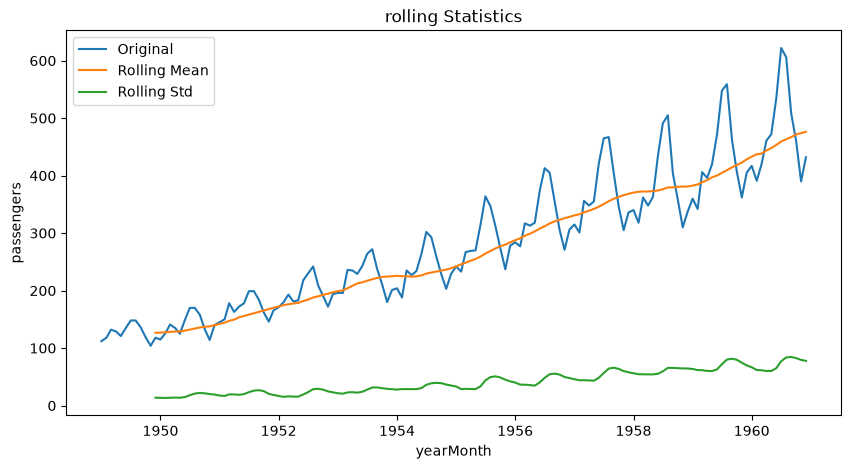

In [8]:
# Test Stationary
test_stationarity(airP,'passengers')

            passengers  rollMean  rollStd  shift  shiftDiff
yearMonth                                                  
1949-01-01         112       NaN      NaN    NaN        NaN
1949-02-01         118       NaN      NaN  112.0        6.0
1949-03-01         132       NaN      NaN  118.0       14.0
1949-04-01         129       NaN      NaN  132.0       -3.0
1949-05-01         121       NaN      NaN  129.0       -8.0
1949-06-01         135       NaN      NaN  121.0       14.0
1949-07-01         148       NaN      NaN  135.0       13.0
1949-08-01         148       NaN      NaN  148.0        0.0
1949-09-01         136       NaN      NaN  148.0      -12.0
1949-10-01         119       NaN      NaN  136.0      -17.0
ADF p-value : 0.0707
The Time Series is not Stationary (fail to reject H0).


C:\Users\PGCP-AI.STUDENTSDC\AppData\Local\Temp\ipykernel_14584\384336574.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(dataFrame[var])


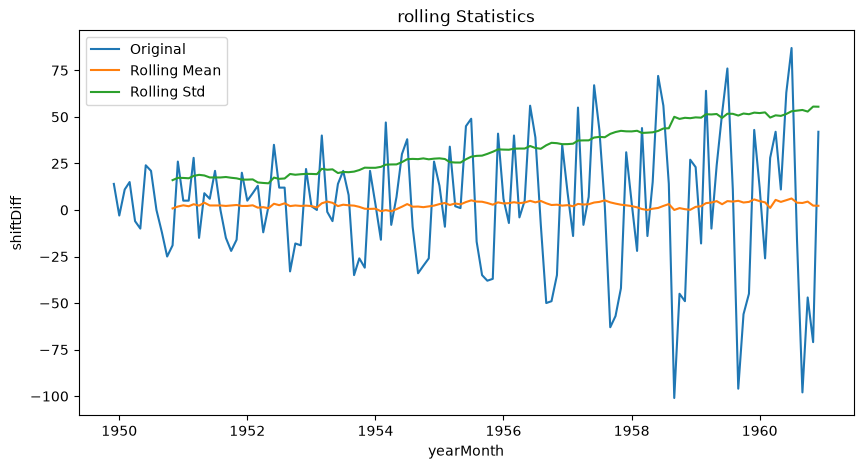

In [9]:
# Not Stationary...Try with diff of 1
airP['shift'] = airP.passengers.shift(1)
airP['shiftDiff'] = airP['passengers'] - airP['shift']
print(airP.head(10))
test_stationarity(airP.dropna(),'shiftDiff')

            passengers  rollMean  rollStd  shift  shiftDiff
yearMonth                                                  
1949-01-01         112       NaN      NaN    NaN        NaN
1949-02-01         118       NaN      NaN    NaN        NaN
1949-03-01         132       NaN      NaN  112.0       20.0
1949-04-01         129       NaN      NaN  118.0       11.0
1949-05-01         121       NaN      NaN  132.0      -11.0
1949-06-01         135       NaN      NaN  129.0        6.0
1949-07-01         148       NaN      NaN  121.0       27.0
1949-08-01         148       NaN      NaN  135.0       13.0
1949-09-01         136       NaN      NaN  148.0      -12.0
1949-10-01         119       NaN      NaN  148.0      -29.0
ADF p-value : 0.0397
The Time Series is Stationary (reject H0).


C:\Users\PGCP-AI.STUDENTSDC\AppData\Local\Temp\ipykernel_14584\384336574.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(dataFrame[var])


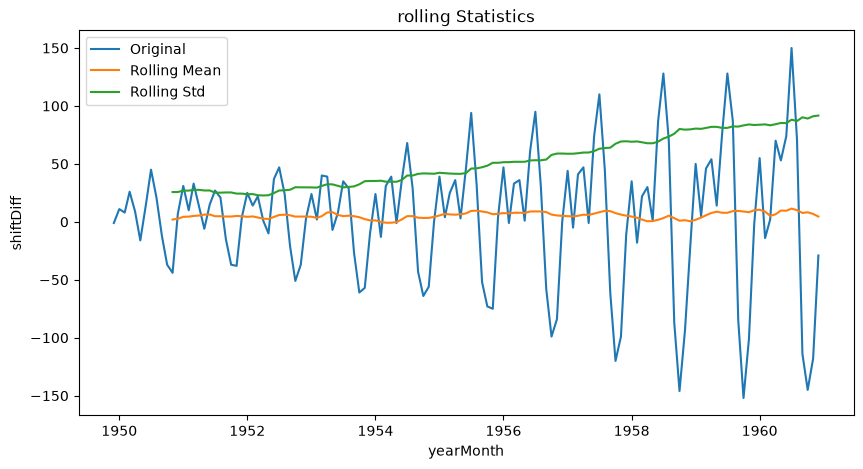

In [10]:
# Not Stationary...Try with diff of 2
airP['shift'] = airP.passengers.shift(2)
airP['shiftDiff'] = airP['passengers'] - airP['shift']
print(airP.head(10))
test_stationarity(airP.dropna(),'shiftDiff')

In [15]:
# For ACF - Differencing of 2 and 12
airP['secondDiff'] = airP['passengers'].diff(2)
airP['Diff12'] = airP['passengers'].diff(12)

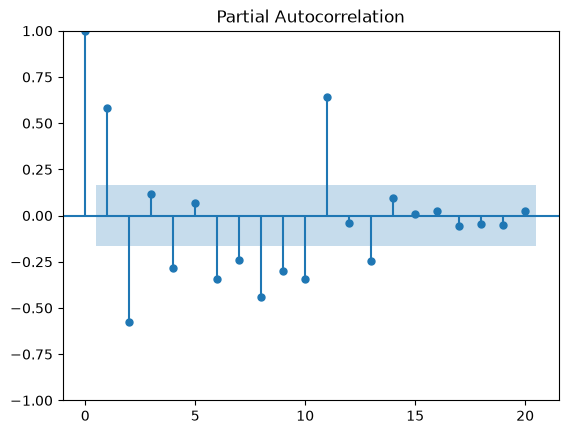

In [16]:
# PACF and ACF Plots
plot_pacf(airP['secondDiff'].dropna(), lags=20) # -> gives P(i.e AR) value for the ARIMA function 
plt.show()

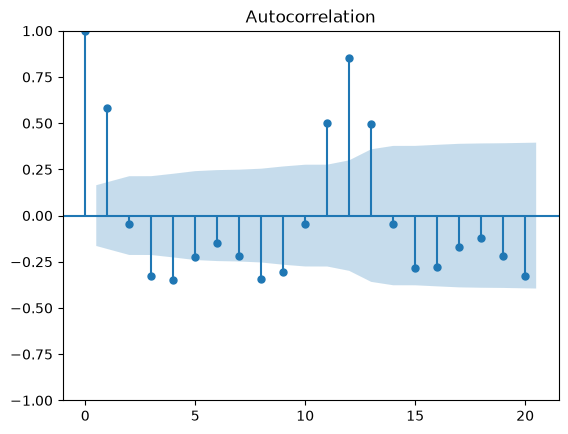

In [17]:
# PACF and ACF Plots
plot_acf(airP['secondDiff'].dropna(), lags=20) # -> gives Q(i.e MA) value for the ARIMA function 
plt.show()

In [21]:
# ttrain test split
train_size = int(len(airP) * 0.7)
train = airP.iloc[:train_size]
test = airP.iloc[train_size:]

In [24]:
# Arima Model 
model_arima = ARIMA(train['passengers'], order=(1,2,1))
model_arima_fit  = model_arima.fit()
arima_pred = model_arima_fit.predict(start = len(train), end=len(airP)-1)

C:\Users\PGCP-AI.STUDENTSDC\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\PGCP-AI.STUDENTSDC\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\PGCP-AI.STUDENTSDC\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


In [25]:
# Add ARIMA prediction to dataframe
airP['arimaPred'] = np.nan
airP.iloc[train_size:,airP.columns.get_loc('arimaPred')] = arima_pred.values
airP.tail()

,passengers,rollMean,rollStd,shift,shiftDiff,secondDiff,Diff12,arimaPred
yearMonth,,,,,,,,
1960-08-01,606,463.333333,83.630500,535.0,71.0,71.0,47.0,439.708776
1960-09-01,508,467.083333,84.617276,622.0,-114.0,-114.0,45.0,442.074522
1960-10-01,461,471.583333,82.541954,606.0,-145.0,-145.0,54.0,444.440267
1960-11-01,390,473.916667,79.502382,508.0,-118.0,-118.0,28.0,446.806013
1960-12-01,432,476.166667,77.737125,461.0,-29.0,-29.0,27.0,449.171759


In [32]:
airP.columns.get_loc('arimaPred')

7

In [33]:
# SARIMAX Model 

In [34]:
# to calculate P and Q for SARIMAX
airP['diff_combined'] = airP['passengers'].diff(2).diff(12)

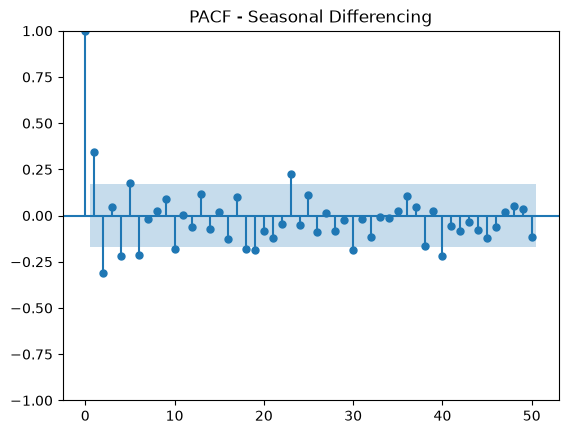

In [35]:
plot_pacf(airP['diff_combined'].dropna(), lags=50) 
plt.title('PACF - Seasonal Differencing')
plt.show()

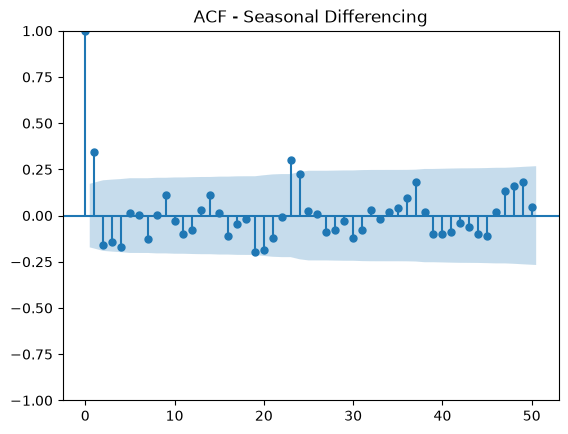

In [36]:
plot_acf(airP['diff_combined'].dropna(), lags=50) 
plt.title('ACF - Seasonal Differencing')
plt.show()

In [37]:
model_sarimax = SARIMAX(train['passengers'],order=(1,2,1),seasonal_order=(1,2,1,12))
model_sarimax_fit = model_sarimax.fit()
sarimax_pred = model_sarimax_fit.predict(start = len(train), end=len(airP)-1)

C:\Users\PGCP-AI.STUDENTSDC\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\PGCP-AI.STUDENTSDC\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


In [39]:
# Add SARIMAX Prediction to datframe
airP['sarimaxPred'] = np.nan
airP.iloc[train_size:,airP.columns.get_loc('sarimaxPred')] = sarimax_pred.values
airP.tail()

,passengers,rollMean,rollStd,shift,shiftDiff,secondDiff,Diff12,arimaPred,diff_combined,sarimaxPred
yearMonth,,,,,,,,,,
1960-08-01,606,463.333333,83.630500,535.0,71.0,71.0,47.0,439.708776,-16.0,594.462517
1960-09-01,508,467.083333,84.617276,622.0,-114.0,-114.0,45.0,442.074522,-29.0,524.220370
1960-10-01,461,471.583333,82.541954,606.0,-145.0,-145.0,54.0,444.440267,7.0,458.563265
1960-11-01,390,473.916667,79.502382,508.0,-118.0,-118.0,28.0,446.806013,-17.0,408.926329
1960-12-01,432,476.166667,77.737125,461.0,-29.0,-29.0,27.0,449.171759,-27.0,457.034961


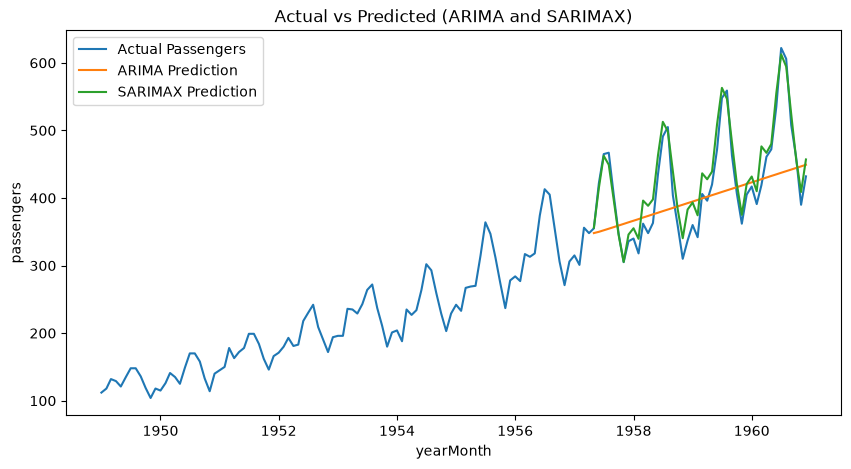

In [40]:
# Plot Predictions
plt.figure(figsize = (10,5))
sns.lineplot(x=airP.index, y=airP['passengers'],label='Actual Passengers')
sns.lineplot(x=airP.index, y=airP['arimaPred'],label='ARIMA Prediction')
sns.lineplot(x=airP.index, y=airP['sarimaxPred'],label='SARIMAX Prediction')
plt.title('Actual vs Predicted (ARIMA and SARIMAX)')
plt.legend()
plt.show()

In [43]:
# Future Forecast using SARIMAX
future_dates = pd.DataFrame(pd.date_range(start='1961-01-01',end='1962-01-01',freq='MS'),columns=['Dates'])
future_dates.set_index('Dates',inplace=True)
future_dates.head()

""
Dates
1961-01-01
1961-02-01
1961-03-01
1961-04-01
1961-05-01


In [44]:
future_forecast = model_sarimax_fit.predict(start=future_dates.index[0],end=future_dates.index[-1])
future_forecast

1961-01-01    468.933621
1961-02-01    444.070896
1961-03-01    515.028190
1961-04-01    504.549541
1961-05-01    519.275804
1961-06-01    599.661571
1961-07-01    660.646657
1961-08-01    640.481400
1961-09-01    564.495092
1961-10-01    494.159116
1961-11-01    440.997133
1961-12-01    491.739382
1962-01-01    504.321086
Freq: MS, Name: predicted_mean, dtype: float64

C:\Users\PGCP-AI.STUDENTSDC\AppData\Local\Programs\Python\Python314\Lib\site-packages\pandas\plotting\_matplotlib\core.py:997: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  return ax.plot(*args, **kwds)


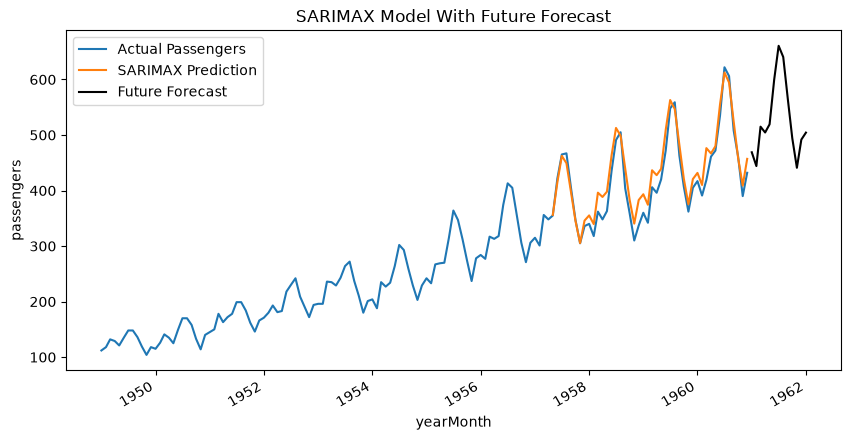

In [46]:
# Plot future forecast
plt.figure(figsize = (10,5))
sns.lineplot(x=airP.index, y=airP['passengers'],label='Actual Passengers')
sns.lineplot(x=airP.index, y=airP['sarimaxPred'],label='SARIMAX Prediction')
future_forecast.plot(color='black',label='Future Forecast')
plt.title('SARIMAX Model With Future Forecast')
plt.legend()
plt.show()

In [47]:
# Model Evaluation 
actual = test['passengers']

In [48]:
# ARIMA Metrics
arima_mae = mean_absolute_error(actual,arima_pred)
arima_mse = mean_squared_error(actual,arima_pred)
arima_rmse = math.sqrt(arima_mse)
arima_r2 = r2_score(actual,arima_pred)
print(f'ARIMA -> MAE : {arima_mae:.2f}, MSE : {arima_mse:.2f}, RMSE : {arima_rmse:.2f}, R2 : {arima_r2:.2f}')

ARIMA -> MAE : 53.92, MSE : 5039.61, RMSE : 70.99, R2 : 0.14


In [50]:
# SARIMAX Metrics
sarimax_mae = mean_absolute_error(actual,sarimax_pred)
sarimax_mse = mean_squared_error(actual,sarimax_pred)
sarimax_rmse = math.sqrt(sarimax_mse)
sarimax_r2 = r2_score(actual,sarimax_pred)
print(f'SARIMAX -> MAE : {sarimax_mae:.2f}, MSE : {sarimax_mse:.2f}, RMSE : {sarimax_rmse:.2f}, R2 : {sarimax_r2:.2f}')

SARIMAX -> MAE : 19.75, MSE : 556.92, RMSE : 23.60, R2 : 0.90
